# ACORN: Active Continuous-Score Occupancy Modeling

This notebook demonstrates how to apply **Active Continuous-Score Occupancy Modeling (ACORN)** to a new camera trap dataset.

The first sections handle dataset preparation, while the final section launches a small interactive review interface.

## Step 0: Setup and download the dataset

Run the cells in order in Google Colab (a CPU runtime is sufficient) or a local Jupyter kernel.

In [ ]:
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
candidates = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next(
    (path for path in candidates if (path / "src/occubed").is_dir() and (path / "pyproject.toml").is_file()),
    None,
)
if REPO_ROOT is None:
    if not IN_COLAB:
        raise RuntimeError("Open this notebook from your local ACORN checkout.")
    REPO_ROOT = Path("/content/acorn")
    if not REPO_ROOT.exists():
        subprocess.run(["git", "clone", "https://github.com/timmh/acorn.git", str(REPO_ROOT)], check=True)

# Use the kernel's interpreter and make an editable install visible immediately.
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "biolith==0.1.0", "jax[cpu]==0.6.2", "numpyro==0.19.0",
    "ipywidgets", "pillow", "pytest", "pandas", "matplotlib",
])
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-e", str(REPO_ROOT)])
sys.path.insert(0, str(REPO_ROOT / "src"))
os.environ["JAX_PLATFORMS"] = "cpu"
os.environ["JAX_ENABLE_X64"] = "false"

if IN_COLAB:
    from google.colab import output
    output.enable_custom_widget_manager()

DEMO_DIR = REPO_ROOT / "example"
DEMO_DIR.mkdir(exist_ok=True)
os.chdir(DEMO_DIR)
print(f"Using ACORN checkout: {REPO_ROOT}")

In [ ]:
# Download camera-trap images and metadata, preserving the dataset's directory layout.
DATASET_URL = "https://catalogue.ceh.ac.uk/datastore/eidchub/a657ffc3-8f62-458f-bcb7-30e116807174/"
DATA_ROOT = DEMO_DIR / "data/catalogue.ceh.ac.uk/datastore/eidchub/a657ffc3-8f62-458f-bcb7-30e116807174"
download_marker = DEMO_DIR / ".camera_trap_download_complete"
if not download_marker.exists() or not DATA_ROOT.exists():
    subprocess.run(
        ["wget", "--quiet", "--recursive", "--no-parent", "--no-clobber",
         "--reject=index.html*", "--directory-prefix", str(DEMO_DIR / "data"), DATASET_URL],
        check=True,
    )
    download_marker.touch()
print(f"Dataset: {DATA_ROOT}")

### About the Dataset

The dataset we just downloaded is described in:
Barnett, C.L.; Gashchak, S.; Beresford, N.A.; Wood, M.D. (2022). *Wildlife camera trap photographs from the Chornobyl Exclusion Zone, Ukraine (November 2020 - March 2021) following extensive wildfires.* NERC EDS Environmental Information Data Centre. https://doi.org/10.5285/a657ffc3-8f62-458f-bcb7-30e116807174

It is licensed under the terms of the [Open Government Licence](https://eidc.ceh.ac.uk/licences/OGL/plain).

Study area:
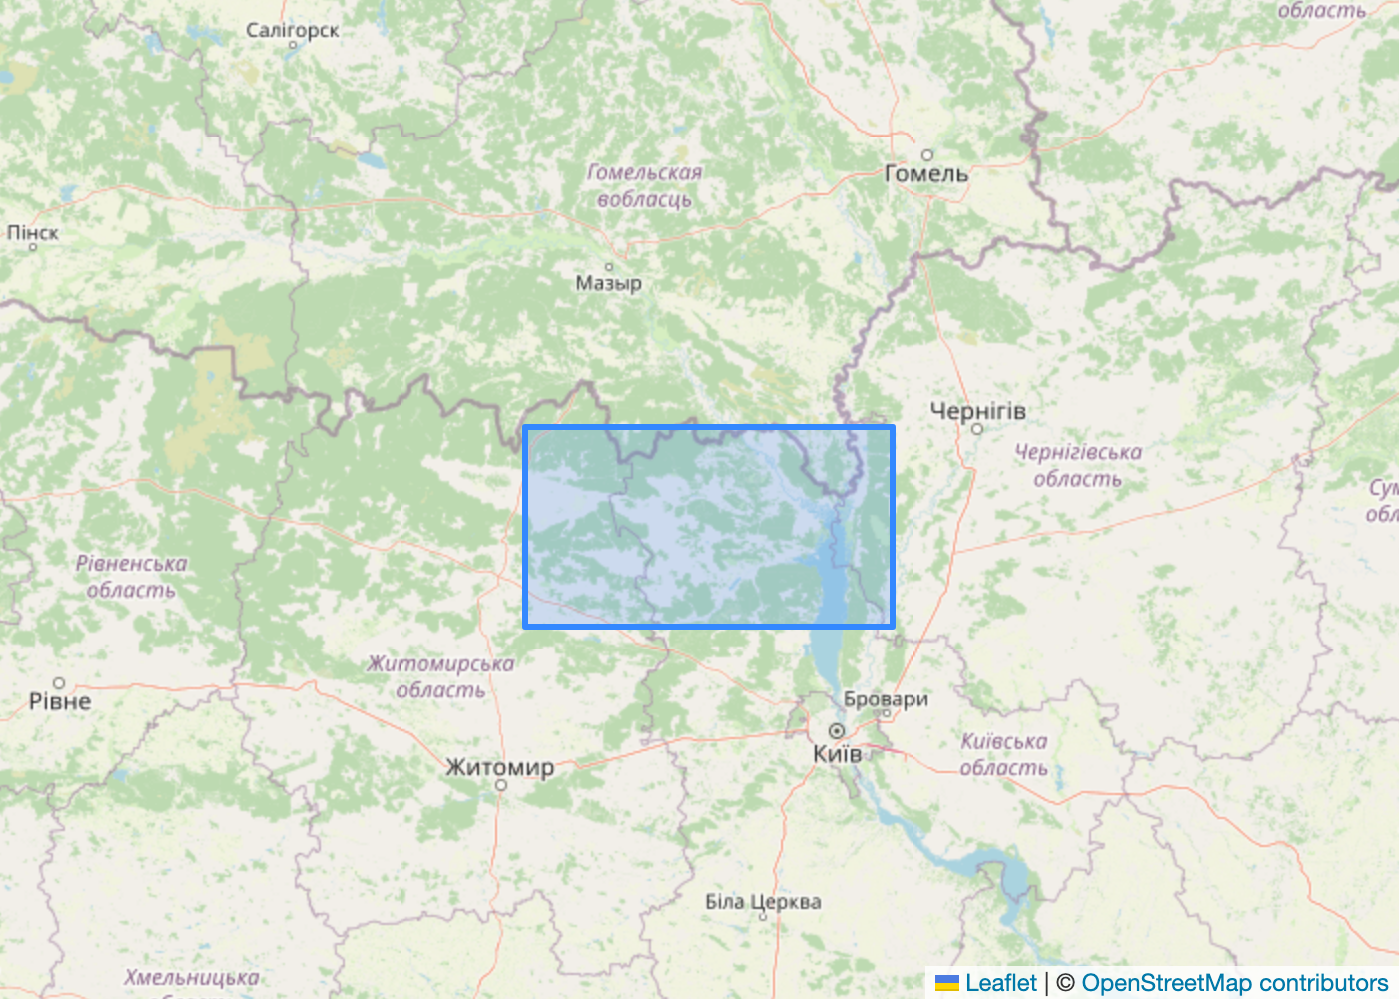

Some example images:
![Example A](https://catalogue.ceh.ac.uk/datastore/eidchub/a657ffc3-8f62-458f-bcb7-30e116807174/Setup2_Site_1/Setup2_Site1_1570/Eurasianelk/IMAG0395.JPG)
![Example B](https://catalogue.ceh.ac.uk/datastore/eidchub/a657ffc3-8f62-458f-bcb7-30e116807174/Setup2_Site_1/Setup2_Site1_1570/Greywolf/IMAG0342.JPG)
![Example C](https://catalogue.ceh.ac.uk/datastore/eidchub/a657ffc3-8f62-458f-bcb7-30e116807174/Setup2_Site_1/Setup2_Site1_1579/Eurasianlynx/IMAG0038.JPG)

## Step 1: Choose the score source

Keep `USE_PRECOMPUTED_PREDICTIONS = True` to download pre-computed SpeciesNet predictions. Set it to `False` before running these cells to install and run SpeciesNet yourself.

In [ ]:
USE_PRECOMPUTED_PREDICTIONS = True
PREDICTIONS_PATH = DEMO_DIR / "predictions.json"

if not USE_PRECOMPUTED_PREDICTIONS:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "speciesnet==5.0.5"])

In [ ]:
# Define the species supported by this example.
# See https://www.kaggle.com/models/google/speciesnet?select=taxonomy_release.txt
# for the complete SpeciesNet taxonomy.
species_of_interest = """
ce9a5481-b3f7-4e42-8b8b-382f601fded0;mammalia;lagomorpha;leporidae;lepus;europaeus;european hare
429257d4-3ef2-47fb-b849-66ee6c107346;mammalia;cetartiodactyla;cervidae;alces;alces;moose
ee8d5a89-f82e-4323-80e2-0ffc9487ebaf;mammalia;carnivora;canidae;canis;lupus;grey wolf
eb3829b0-772e-4088-ae90-f11b9fe38284;mammalia;cetartiodactyla;cervidae;cervus;elaphus;red deer
ac0e8ba7-7261-4d17-8645-11ed3d02165a;mammalia;carnivora;canidae;vulpes;vulpes;red fox
317171d7-d306-4e71-9a4a-33e62012076b;mammalia;cetartiodactyla;cervidae;capreolus;capreolus;european roe deer
19fd235e-d808-4e22-bfae-42491045b763;mammalia;perissodactyla;equidae;equus;ferus;przewalski's horse
ea3fb6be-f489-4c8c-9002-bc2d0a22d007;mammalia;carnivora;felidae;lynx;lynx;eurasian lynx
73baf300-5592-4ab5-9da8-7da898477934;mammalia;carnivora;mustelidae;meles;meles;eurasian badger
d372cda5-a8ca-4b7b-97ed-4e4fab9c9b4b;mammalia;cetartiodactyla;suidae;sus;scrofa;wild boar
746d3e98-64af-4897-9cd3-c09b169a8c69;mammalia;carnivora;canidae;nyctereutes;procyonoides;raccoon dog
0f132580-6fc9-4ffa-8e6d-39cdc00c359e;mammalia;carnivora;mustelidae;lutra;lutra;eurasian otter
"""

with open("target_species.txt", "w", encoding="utf-8") as file:
    file.write(species_of_interest)

## Step 2: Score the images

In [ ]:
# Run SpeciesNet only when requested; the default path uses precomputed scores.
if not USE_PRECOMPUTED_PREDICTIONS:
    os.environ["DISABLE_COLAB_CACHE"] = "1"
    subprocess.run(
        [sys.executable, "-m", "speciesnet.scripts.run_model",
         "--noprogress_bars", "--folders", str(DATA_ROOT),
         "--predictions_json", str(PREDICTIONS_PATH),
         "--target_species_txt", str(DEMO_DIR / "target_species.txt")],
        check=True,
    )

In [ ]:
# Download once and validate the prediction file before caching it.
if USE_PRECOMPUTED_PREDICTIONS and not PREDICTIONS_PATH.exists():
    import json
    from urllib.request import urlretrieve

    prediction_url = (
        "https://www.dropbox.com/scl/fi/diiiwpesewil64uupl43d/predictions.json"
        "?rlkey=1j274fbid22l9bmmj1pv3whu3&dl=1"
    )
    temporary_path = PREDICTIONS_PATH.with_suffix(".download")
    urlretrieve(prediction_url, temporary_path)
    with temporary_path.open(encoding="utf-8") as file:
        downloaded = json.load(file)
    if not isinstance(downloaded.get("predictions"), list) or not downloaded["predictions"]:
        raise ValueError("The download does not contain SpeciesNet predictions.")
    temporary_path.replace(PREDICTIONS_PATH)
print(f"Predictions: {PREDICTIONS_PATH}")

## Step 3: Prepare location-day occupancy replicates

In [ ]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

In [ ]:
# Load and join the camera-site metadata.
site_descriptions = pd.read_csv(
    DATA_ROOT / "CHAR_Nov_2020_Mar_2021_Camera_Trap_Site_Descriptions.csv",
    keep_default_na=False, na_values=[""],  # The burn category 'None' is not missing.
)
site_details = pd.read_csv(
    DATA_ROOT / "CHAR_Nov_2020_Mar_2021_Camera_Trap_Details.csv"
)
site_metadata = pd.merge(
    site_descriptions.rename(columns=lambda column: column.replace(" ", "")),
    site_details.rename(columns=lambda column: column.replace(" ", "")),
    on=["Site", "Camera_Location_Identifier"],
)
site_metadata.head()

In [ ]:
# Encode burn severity and index covariates by camera location.
burn_column = (
    "Degree_Of_Burn_Of_Area_Affected_By_Fire_Within_200_Metre_Radius_"
    "Of_Camera_Location_Jun_2020"
)
site_metadata["DegreeOfBurnArea"] = (
    site_metadata[burn_column]
    .str.split(" ", n=1, expand=True)
    .iloc[:, 0]
    .map({"None": 0, "Low": 1, "High": 2, "Very": 3})
)
site_metadata["Camera_Location_Identifier"] = site_metadata[
    "Camera_Location_Identifier"
].astype(int)
site_metadata = site_metadata.set_index("Camera_Location_Identifier").sort_index()
site_metadata[["DegreeOfBurnArea"]].head()

In [ ]:
# Load image metadata. Dataset labels are retained only for optional evaluation;
# the active-review model will use labels entered through the interface.
image_metadata = pd.read_csv(
    DATA_ROOT / "CHAR_Nov_2020_Mar_2021_Camera_Trap_Image_Catalogue.csv"
)
image_metadata["DateTime"] = pd.to_datetime(
    image_metadata["Date"] + " " + image_metadata["Time"],
    format="%d/%m/%y %H:%M:%S",
)

species_mapping = {
    "Brown hare": "european hare",
    "Eurasian elk": "moose",
    "Grey wolf": "grey wolf",
    "Red deer": "red deer",
    "Red fox": "red fox",
    "Roe deer": "european roe deer",
    "Przewalski's horse": "przewalski's horse",
    "Eurasian lynx": "eurasian lynx",
    "European badger": "eurasian badger",
    "Wild boar": "wild boar",
    "Raccoon dog": "raccoon dog",
    "European otter": "eurasian otter",
}
image_metadata["Dataset_Label"] = image_metadata["Species_Common_Name"].map(
    species_mapping
)
image_metadata.head()

In [ ]:
# Join all target-species logits in one table rather than repeatedly scanning metadata.
with PREDICTIONS_PATH.open(encoding="utf-8") as file:
    predictions = json.load(file)

score_rows = []
num_failures = 0
for prediction in predictions["predictions"]:
    if prediction.get("failures"):
        num_failures += 1
        continue

    prediction_path = Path(prediction["filepath"])
    setup, site, location = prediction_path.parents[1].name.split("_")
    row = {
        "Site": int(site.removeprefix("Site")),
        "Camera_Location_Identifier": int(location),
        "Image_Filename": prediction_path.name,
    }
    classifications = prediction["classifications"]
    for label, logit in zip(
        classifications["target_classes"], classifications["target_logits"], strict=True
    ):
        species_name = label.split(";")[-1]
        if species_name in species_mapping.values():
            row[species_name] = float(logit)
    score_rows.append(row)

join_columns = ["Site", "Camera_Location_Identifier", "Image_Filename"]
score_frame = pd.DataFrame(score_rows)
if score_frame.empty:
    raise ValueError("No successful SpeciesNet predictions were found.")
metadata_keys = pd.MultiIndex.from_frame(image_metadata[join_columns])
prediction_keys = pd.MultiIndex.from_frame(score_frame[join_columns])
if not prediction_keys.isin(metadata_keys).all():
    raise ValueError("Some predictions do not match an image metadata row.")
missing_species = set(species_mapping.values()) - set(score_frame.columns)
if missing_species:
    raise ValueError(f"Predictions lack target-species logits: {sorted(missing_species)}")
image_metadata = image_metadata.drop(
    columns=list(species_mapping.values()), errors="ignore"
).merge(score_frame, on=join_columns, how="left", validate="one_to_one")

print(f"Loaded scores for {len(score_rows):,} images; skipped {num_failures:,} failed predictions.")

In [ ]:
print("Available species:\n" + "\n".join(species_mapping.values()))

# Change this value to review a different supported species.
target_species = "grey wolf"
print(f"\nTarget species: {target_species}")

In [ ]:
# Map metadata rows to local image files with one filesystem scan.
image_path_lookup = {}
for path in DATA_ROOT.rglob("*"):
    if not path.is_file() or path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
        continue
    try:
        location_id = int(path.parents[1].name.rsplit("_", 1)[-1])
    except (IndexError, ValueError):
        continue
    image_path_lookup[(location_id, path.name.lower())] = str(path)

image_metadata["ImagePath"] = [
    image_path_lookup.get((int(location_id), str(filename).lower()))
    for location_id, filename in image_metadata[
        ["Camera_Location_Identifier", "Image_Filename"]
    ].itertuples(index=False, name=None)
]
image_metadata["ReplicateDate"] = image_metadata["DateTime"].dt.normalize()

# ACORN's camera-trap replicate is a location-day: the score is the maximum
# target logit that day, and a review asks whether any image contains the species.
review_units = (
    image_metadata.groupby(
        ["Camera_Location_Identifier", "ReplicateDate"], as_index=False
    )
    .agg(
        Score=(target_species, "max"),
        ImagePaths=(
            "ImagePath",
            lambda values: tuple(
                dict.fromkeys(
                    value
                    for value in values
                    if isinstance(value, str) and value
                )
            ),
        ),
        ImageCount=("ImagePath", lambda values: values.notna().sum()),
    )
    .dropna(subset=["Score"])
)
review_units = review_units[review_units["ImageCount"] > 0].copy()

# Keep sites with a usable burn-severity covariate and normalize it.
available_sites = sorted(
    set(review_units["Camera_Location_Identifier"])
    & set(site_metadata.index[site_metadata["DegreeOfBurnArea"].notna()])
)
review_units = review_units[
    review_units["Camera_Location_Identifier"].isin(available_sites)
].sort_values(["Camera_Location_Identifier", "ReplicateDate"])
site_covariate_frame = site_metadata.loc[available_sites, ["DegreeOfBurnArea"]]
site_covariate_scale = site_covariate_frame.std(ddof=0).replace(0, 1).fillna(1)
acorn_site_covs = (
    (site_covariate_frame - site_covariate_frame.mean()) / site_covariate_scale
).to_numpy(dtype=float)

# Pack ragged location-days into ACORN's (species, site, season, replicate) layout.
site_to_index = {site_id: index for index, site_id in enumerate(available_sites)}
review_units["SiteIndex"] = review_units["Camera_Location_Identifier"].map(
    site_to_index
)
review_units["ReplicateIndex"] = review_units.groupby("SiteIndex").cumcount()
max_replicates = int(review_units.groupby("SiteIndex").size().max())
acorn_scores = np.full(
    (1, len(available_sites), 1, max_replicates), np.nan, dtype=float
)
acorn_obs_covs = np.full(
    (len(available_sites), 1, max_replicates, 1), np.nan, dtype=float
)

# The tutorial has no sequence IDs, so log image count is used as a daily-effort proxy.
log_effort = np.log(np.maximum(review_units["ImageCount"].to_numpy(float), 1.0))
effort_scale = float(log_effort.std())
if not np.isfinite(effort_scale) or effort_scale == 0:
    effort_scale = 1.0
review_units["NormalizedLogEffort"] = (log_effort - log_effort.mean()) / effort_scale
unit_lookup = {}
for row in review_units.itertuples(index=False):
    coordinate = (int(row.SiteIndex), 0, int(row.ReplicateIndex))
    acorn_scores[(0, *coordinate)] = float(row.Score)
    acorn_obs_covs[coordinate] = float(row.NormalizedLogEffort)
    unit_lookup[coordinate] = row

reviewed_f = np.full_like(acorn_scores, np.nan, dtype=float)
print(
    f"Prepared {len(review_units):,} reviewable location-days from "
    f"{len(available_sites):,} camera sites (up to {max_replicates} days/site)."
)

## Step 4: Fit ACORN and actively review images

At each round the code below:

1. fits the two-component Normal score calibration using all finite logits plus verified labels
2. fits the calibrated continuous-score occupancy model, replacing score evidence with a reviewer label wherever one is available
3. ranks unreviewed location-days by expected information gain on site occupancy probabilities and the occupancy/detection coefficients
4. displays the selected batch for review.

The default settings use one MCMC chain and a small number of samples for responsiveness. Increase the warmup, samples, chains and assess model convergence before drawing scientific conclusions.

In [ ]:
# The tutorial uses the public package's model and acquisition functions directly.
import occubed
print(f"ACORN package: {occubed.__file__}")

In [ ]:
# Use CPU for the relatively small occupancy model, leaving a notebook GPU free for SpeciesNet.
os.environ["JAX_PLATFORMS"] = "cpu"
os.environ["JAX_ENABLE_X64"] = "false"

import jax.numpy as jnp
from biolith.utils import fit
from occubed.models import occu_cs_calibrated
from occubed.fit_utils import disable_numpyro_mcmc_caching
from occubed.review_policies import (
    DEFAULT_CUT_NORMAL_SCORE_CALIBRATION_KWARGS,
    TARGET_EIG_ACQUISITION_CONFIG,
    TARGET_EIG_TARGET_CONFIG,
    build_cs_selection_state,
    count_reviewed_positives,
    fit_cut_normal_score_calibration,
    select_calibrated_target_eig_samples,
    select_top_acquisition_samples,
)

disable_numpyro_mcmc_caching()

BATCH_SIZE = 4
MCMC_KWARGS = dict(num_warmup=200, num_samples=200, num_chains=1, timeout=600)
CALIBRATION_KWARGS = {
    **DEFAULT_CUT_NORMAL_SCORE_CALIBRATION_KWARGS,
    "score_calibration_num_warmup": 100,
    "score_calibration_num_samples": 100,
    "score_calibration_num_draws": 8,
}

acorn_state = {
    "round": 0,
    "results": None,
    "calibration": None,
    "score_log_bf": None,
    "score_log_bf_draws": None,
    "selection_state": None,
    "diagnostics": None,
    "strategy": None,
    "batch": [],
    "pending": {},
    "history": [],
}

In [ ]:
def fit_acorn_and_select_batch():
    """Refit decoupled ACORN, then select the next review batch."""
    round_index = int(acorn_state["round"])
    calibration_kwargs = {
        **CALIBRATION_KWARGS,
        "score_calibration_random_seed": round_index,
    }
    calibration, score_log_bf, score_log_bf_draws = (
        fit_cut_normal_score_calibration(
            acorn_scores,
            reviewed_f,
            calibration_kwargs,
        )
    )
    results = fit(
        occu_cs_calibrated,
        site_covs=acorn_site_covs,
        obs_covs=acorn_obs_covs,
        score_log_bf=jnp.asarray(score_log_bf),
        verified_f=jnp.asarray(reviewed_f),
        random_seed=round_index,
        **MCMC_KWARGS,
    )
    selection_state = build_cs_selection_state(
        occu_cs_calibrated,
        results,
        acorn_scores,
        acorn_site_covs,
        acorn_obs_covs,
        reviewed_f,
        score_log_bf=score_log_bf,
        score_log_bf_draws=score_log_bf_draws,
    )
    reviewable = np.asarray(selection_state["reviewable"], dtype=bool)
    n_to_select = min(BATCH_SIZE, int(reviewable.sum()))

    diagnostics = None
    if n_to_select == 0:
        selected = np.zeros_like(reviewable)
        strategy = "complete"
    elif count_reviewed_positives(reviewed_f) == 0:
        # This is the same calibration-seeding rule used by the experiment loop.
        selected = select_top_acquisition_samples(
            selection_state["max_score"], reviewable, n_to_select
        )
        strategy = "high-score calibration seed"
    else:
        selected, diagnostics = select_calibrated_target_eig_samples(
            results,
            score_log_bf,
            score_log_bf_draws,
            acorn_site_covs,
            acorn_obs_covs,
            reviewed_f,
            reviewable,
            n_to_select,
            target_config=TARGET_EIG_TARGET_CONFIG,
            acquisition_config=TARGET_EIG_ACQUISITION_CONFIG,
        )
        strategy = "decoupled TargetEIG"

    if int(np.asarray(selected).sum()) != n_to_select:
        raise RuntimeError("Acquisition did not return the requested review batch; inspect nonfinite utilities.")
    batch = [tuple(map(int, coordinate)) for coordinate in np.argwhere(selected)]
    if diagnostics is None:
        acquisition_values = np.asarray(selection_state["max_score"])
    else:
        acquisition_values = np.asarray(diagnostics["target_eig"])
    batch.sort(key=lambda coordinate: acquisition_values[coordinate], reverse=True)

    acorn_state.update(
        results=results,
        calibration=calibration,
        score_log_bf=score_log_bf,
        score_log_bf_draws=score_log_bf_draws,
        selection_state=selection_state,
        diagnostics=diagnostics,
        strategy=strategy,
        batch=batch,
        pending={},
    )
    return batch

In [ ]:
from io import BytesIO

import ipywidgets as widgets
from PIL import Image, ImageOps


def image_bytes(path, max_size=(460, 320)):
    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image).convert("RGB")
        image.thumbnail(max_size)
        buffer = BytesIO()
        image.save(buffer, format="JPEG", quality=88)
    return buffer.getvalue()


def make_gallery(paths):
    """Create a tiny previous/next gallery without loading a whole day at once."""
    paths = tuple(paths)
    image_widget = widgets.Image(format="jpeg", layout=widgets.Layout(max_width="100%"))
    caption = widgets.HTML()
    previous_button = widgets.Button(description="Previous", icon="arrow-left")
    next_button = widgets.Button(description="Next", icon="arrow-right")
    position = {"index": 0}

    def refresh():
        index = position["index"]
        image_widget.value = image_bytes(paths[index])
        caption.value = (
            f"<small>Image {index + 1} of {len(paths)} — "
            f"{Path(paths[index]).name}</small>"
        )
        previous_button.disabled = index == 0
        next_button.disabled = index == len(paths) - 1

    def move(delta):
        def handler(_button):
            position["index"] = min(
                max(position["index"] + delta, 0), len(paths) - 1
            )
            refresh()

        return handler

    previous_button.on_click(move(-1))
    next_button.on_click(move(1))
    refresh()
    return widgets.VBox(
        [
            image_widget,
            caption,
            widgets.HBox([previous_button, next_button]),
        ]
    )


summary_html = widgets.HTML()
instruction_html = widgets.HTML()
batch_output = widgets.Output()
model_output = widgets.Output()
refit_button = widgets.Button(
    description="Re-fit ACORN and choose next batch",
    icon="refresh",
    button_style="primary",
    disabled=True,
    layout=widgets.Layout(width="330px", height="42px"),
)


def update_progress():
    batch_size = len(acorn_state["batch"])
    complete = len(acorn_state["pending"])
    refit_button.disabled = batch_size == 0 or complete != batch_size
    instruction_html.value = (
        f"<b>{complete}/{batch_size} location-days labeled.</b> "
        "Inspect every image in each gallery, then choose one label per location-day."
    )


def update_summary():
    results = acorn_state["results"]
    psi = np.asarray(results.samples["psi"], dtype=float)
    mean_occupancy_draws = psi.reshape(len(psi), -1).mean(axis=1)
    lower, center, upper = np.quantile(mean_occupancy_draws, [0.05, 0.5, 0.95])
    calibration = acorn_state["calibration"]
    reviewed_count = int(np.isfinite(reviewed_f).sum())
    positive_count = int(np.nansum(reviewed_f > 0.5))
    summary_html.value = f"""
    <div style="padding:10px;border:1px solid #ddd;border-radius:6px">
      <b>Round {acorn_state['round']} — {acorn_state['strategy']}</b><br>
      Reviewed: {reviewed_count} location-days ({positive_count} observed).<br>
      Mean occupancy posterior: {center:.3f} (90% interval {lower:.3f}–{upper:.3f}).<br>
      Score calibration means: no detection {calibration.mu0:.2f}, detection {calibration.mu1:.2f}.
    </div>
    """


def render_batch():
    update_summary()
    with batch_output:
        batch_output.clear_output(wait=True)
        if not acorn_state["batch"]:
            display(widgets.HTML("<h3>No unreviewed location-days remain.</h3>"))
            update_progress()
            return

        cards = []
        for coordinate in acorn_state["batch"]:
            unit = unit_lookup[coordinate]
            observed_button = widgets.Button(
                description=f"{target_species.title()} observed",
                icon="check",
                layout=widgets.Layout(width="210px"),
            )
            absent_button = widgets.Button(
                description="Not observed",
                icon="times",
                layout=widgets.Layout(width="160px"),
            )
            label_status = widgets.HTML("<i>Not labeled</i>")

            def set_label(label, coordinate, yes_button, no_button, status):
                def handler(_button):
                    acorn_state["pending"][coordinate] = float(label)
                    yes_button.button_style = "success" if label == 1 else ""
                    no_button.button_style = "danger" if label == 0 else ""
                    status.value = (
                        "<b style='color:#2e7d32'>Species observed</b>"
                        if label == 1
                        else "<b style='color:#b71c1c'>Not observed</b>"
                    )
                    update_progress()

                return handler

            observed_button.on_click(
                set_label(
                    1, coordinate, observed_button, absent_button, label_status
                )
            )
            absent_button.on_click(
                set_label(
                    0, coordinate, observed_button, absent_button, label_status
                )
            )

            if acorn_state["diagnostics"] is None:
                acquisition_text = f"seed score = {float(unit.Score):.2f}"
            else:
                target_eig = float(
                    np.asarray(acorn_state["diagnostics"]["target_eig"])[coordinate]
                )
                acquisition_text = f"TargetEIG = {target_eig:.4f} nats"
            header = widgets.HTML(
                f"<b>Site {unit.Camera_Location_Identifier} — "
                f"{pd.Timestamp(unit.ReplicateDate).date()}</b><br>"
                f"{len(unit.ImagePaths)} images; {acquisition_text}"
            )
            card = widgets.VBox(
                [
                    header,
                    make_gallery(unit.ImagePaths),
                    widgets.HBox([observed_button, absent_button]),
                    label_status,
                ],
                layout=widgets.Layout(
                    border="1px solid #ccc",
                    padding="10px",
                    width="100%",
                ),
            )
            cards.append(card)

        display(
            widgets.GridBox(
                cards,
                layout=widgets.Layout(
                    grid_template_columns="repeat(2, minmax(360px, 1fr))",
                    grid_gap="12px",
                    width="100%",
                ),
            )
        )
    update_progress()


def refit_and_refresh(_button):
    if len(acorn_state["pending"]) != len(acorn_state["batch"]):
        return

    previous_labels = reviewed_f.copy()
    staged_history = []
    for coordinate, label in acorn_state["pending"].items():
        reviewed_f[(0, *coordinate)] = label
        unit = unit_lookup[coordinate]
        staged_history.append(
            {
                "round": acorn_state["round"],
                "site": int(unit.Camera_Location_Identifier),
                "date": str(pd.Timestamp(unit.ReplicateDate).date()),
                "label": int(label),
                "selection_strategy": acorn_state["strategy"],
            }
        )

    old_round = acorn_state["round"]
    acorn_state["round"] = old_round + 1
    refit_button.disabled = True
    instruction_html.value = "<b>Re-fitting calibration and occupancy model…</b>"
    try:
        with model_output:
            model_output.clear_output(wait=True)
            fit_acorn_and_select_batch()
            print("Fit complete; displaying the next batch.")
    except Exception as error:
        reviewed_f[...] = previous_labels
        acorn_state["round"] = old_round
        instruction_html.value = f"<b>Fit failed:</b> {error}"
        refit_button.disabled = False
        raise
    else:
        acorn_state["history"].extend(staged_history)
        render_batch()


refit_button.on_click(refit_and_refresh)
interface = widgets.VBox(
    [summary_html, instruction_html, batch_output, refit_button, model_output],
    layout=widgets.Layout(width="100%"),
)

In [ ]:
# Fit the initial decoupled model and launch the review interface.
display(interface)
with model_output:
    model_output.clear_output(wait=True)
    fit_acorn_and_select_batch()
    print("Initial fit complete.")
render_batch()

### Inspect or export reviewed labels

The interface keeps labels in `reviewed_f` and records committed reviews in `acorn_state["history"]`. After one or more rounds, inspect or save them with:

```python
review_history = pd.DataFrame(acorn_state["history"])
display(review_history)
review_history.to_csv("acorn_review_history.csv", index=False)
```

For a final analysis, increase `MCMC_KWARGS` (especially `num_chains`) and check the usual MCMC diagnostics before interpreting the posterior.